In [ ]:
# Figure 6

Plot successfully saved to: C:\Users\PC1\Desktop\Code_Data\Data\Figure_6\output\Zonal_Exposure_Penalty.png
Plot successfully saved to: C:\Users\PC1\Desktop\Code_Data\Data\Figure_6\output\Zonal_Exposure_Penalty.svg


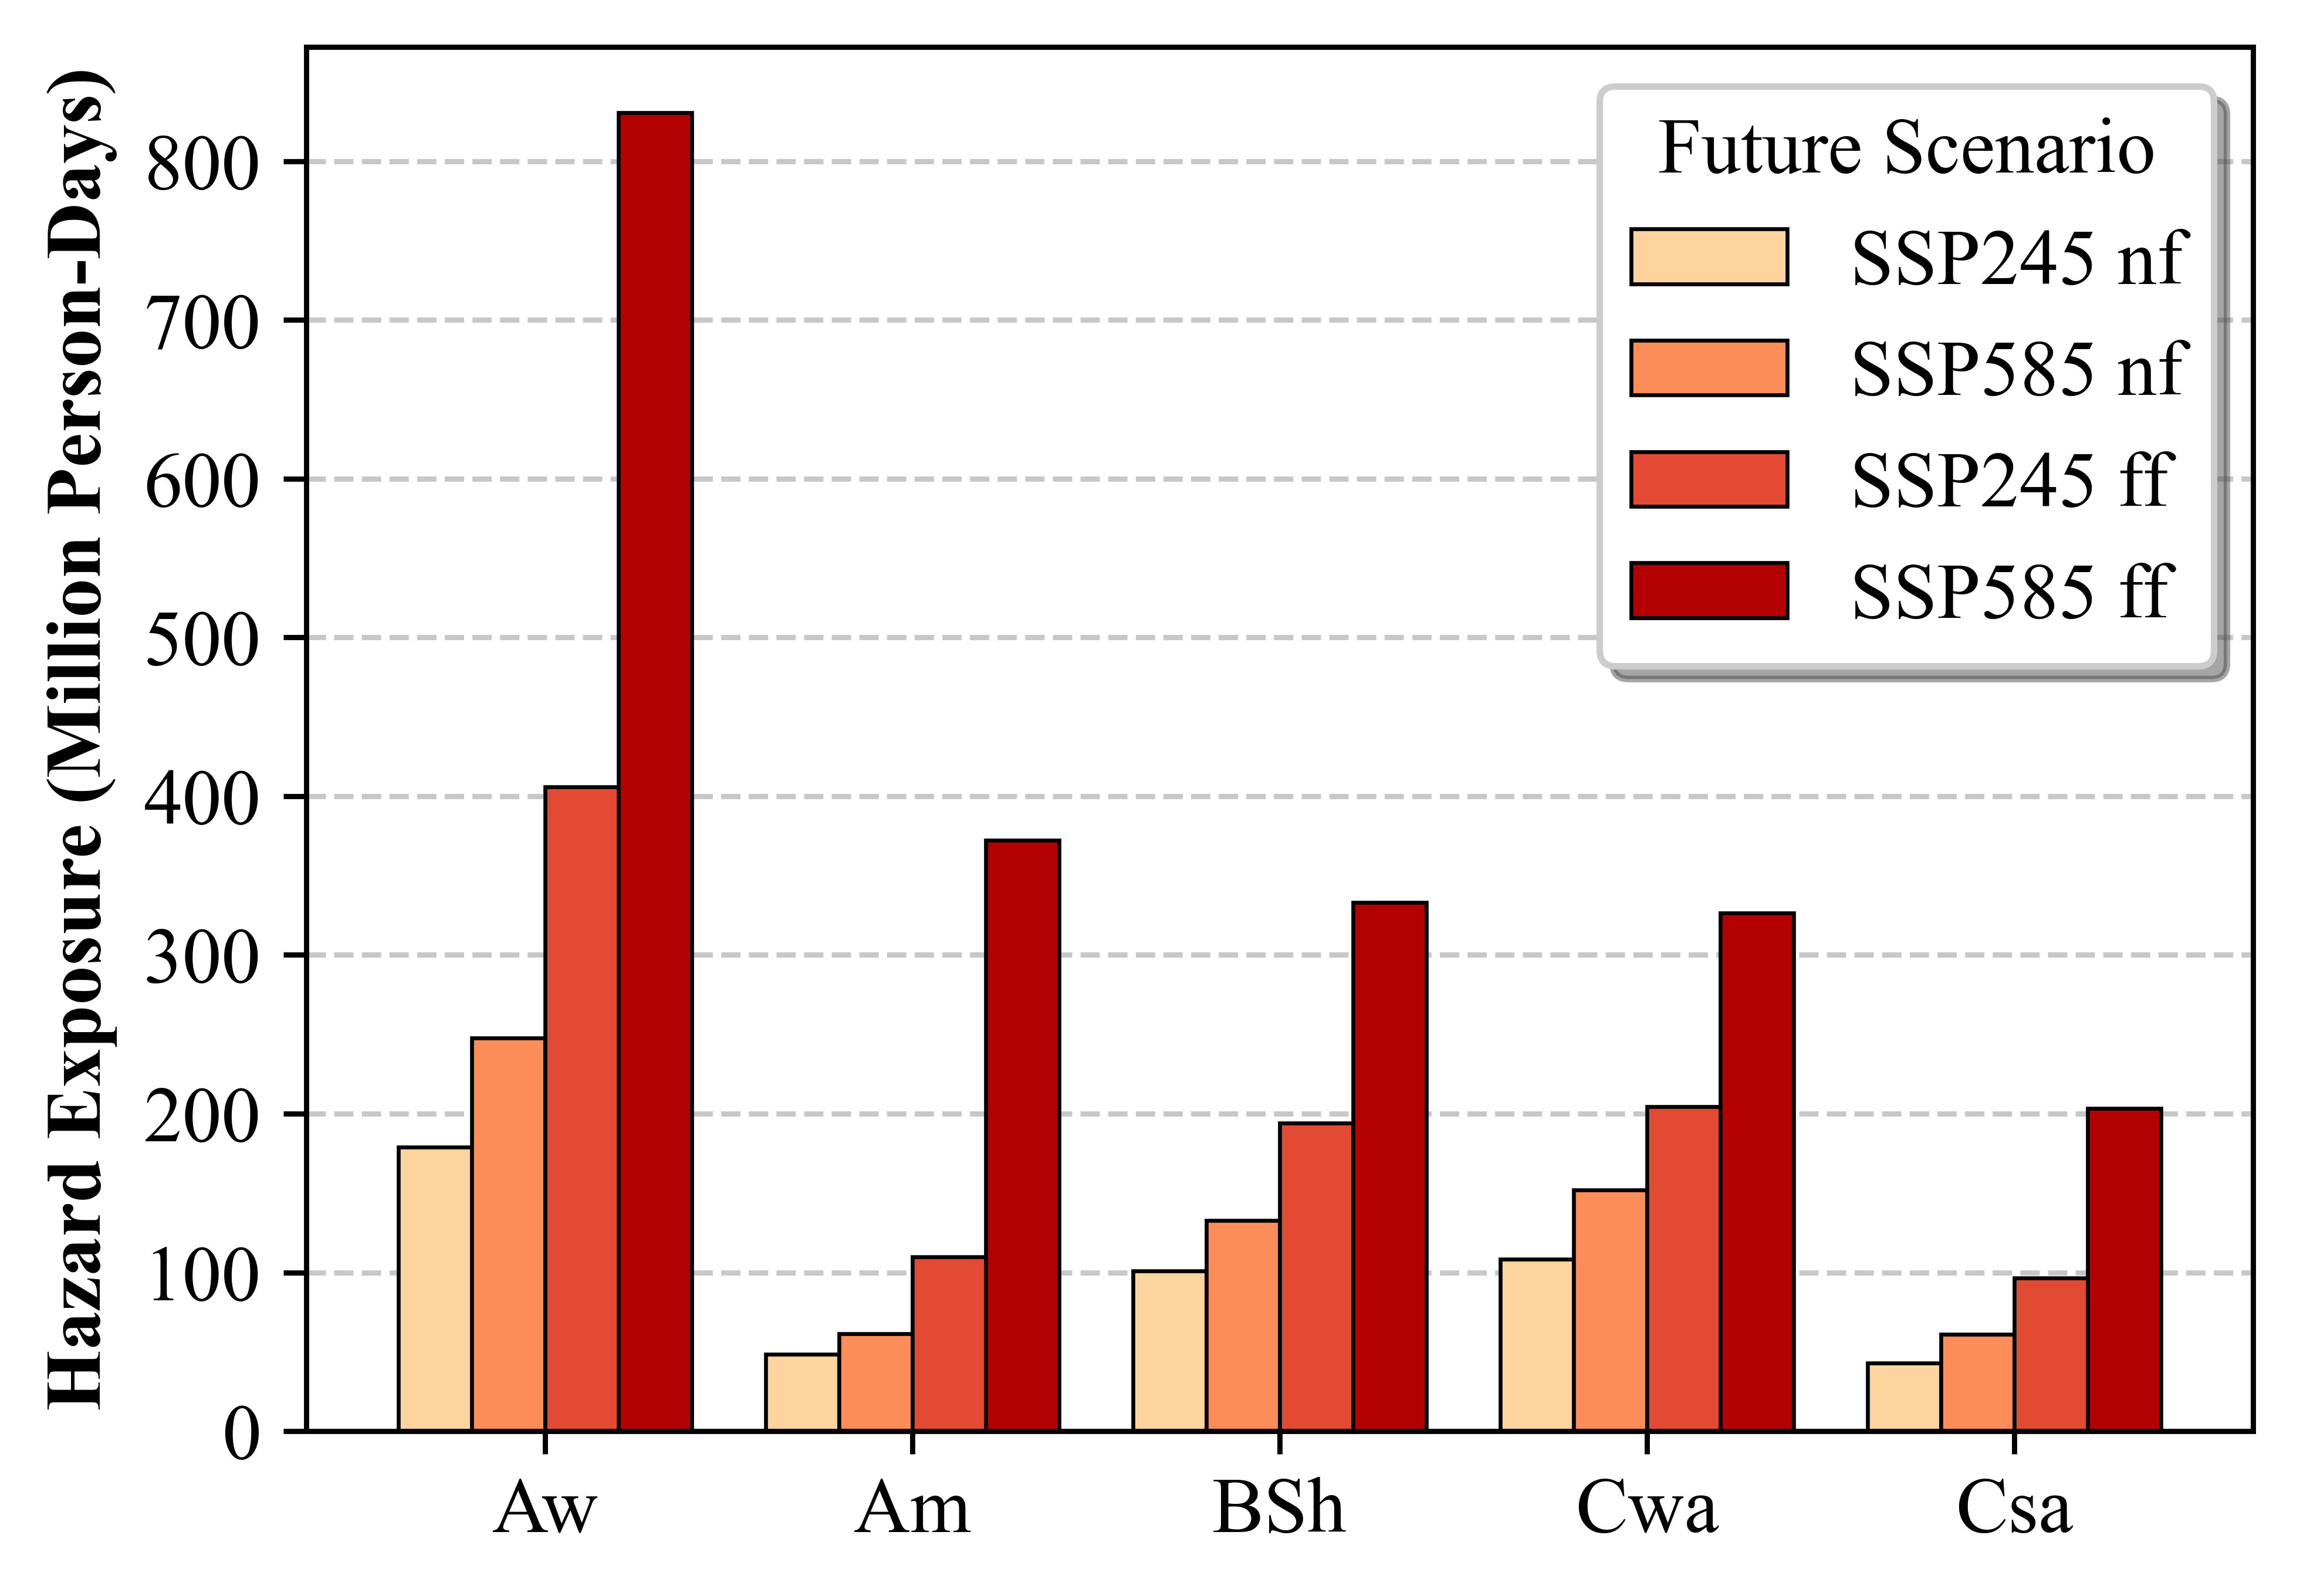

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Output Folder Setup
output_dir = r'C:\Users\PC1\Desktop\Code_Data\Data\Figure_6\output'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 2. Global Font Settings for Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'

# 3. Data Extraction and Processing
# Read input files
df_hi = pd.read_excel(r'C:\Users\PC1\Desktop\Code_Data\Data\Figure_6\HI_Categories_citywise.xlsx')
df_kg = pd.read_csv(r'C:\Users\PC1\Desktop\Code_Data\Data\Figure_6\KG_climate_city.csv')

# Extract the exact names of the last 4 columns containing the scenario data
value_cols = df_hi.columns[-4:].tolist()

# Clean city names to ensure a successful merge between files
df_hi['Join_City'] = df_hi['City.1'].astype(str).str.strip()
df_kg['Join_City'] = df_kg['CityName'].astype(str).str.strip()

# Merge the datasets on the cleaned city names
df_merged = pd.merge(df_hi, df_kg, on='Join_City')

# Group by 'ClimateZone' and compute the mean for the 4 scenario columns
df_grouped = df_merged.groupby('ClimateZone')[value_cols].mean()

# Rename the columns to match the desired legend labels
df_grouped.columns = ['SSP245 nf', 'SSP585 nf', 'SSP245 ff', 'SSP585 ff']

# Reorder the index according to the specific required sequence
zones_order = ['Aw', 'Am', 'BSh', 'Cwa', 'Csa']
df_zones = df_grouped.reindex(zones_order)

# 4. Plotting Setup
# Customization: Change figsize=(width, height) to adjust plot dimensions
fig, ax = plt.subplots(figsize=(5.0, 3.5), dpi=800)

# Customization: Hex color codes for the 4 scenarios (light to dark)
colors = ['#fdd49e', '#fc8d59', '#e34a33', '#b30000']

# Plot the grouped bar chart
df_zones.plot(
    kind='bar', 
    ax=ax, 
    color=colors, 
    width=0.8, 
    edgecolor='black', 
    linewidth=0.6
)

# 5. Formatting & Labels
ax.set_ylabel('Hazard Exposure (Million Person-Days)', 
              fontsize=12, weight='bold', family='Times New Roman')
ax.set_xlabel('')  
# Adjust tick labels
plt.xticks(rotation=0, ha='center', fontsize=12, family='Times New Roman')  
plt.yticks(fontsize=12, family='Times New Roman')

# Customization: Legend settings
plt.legend(
    title='Future Scenario', 
    title_fontsize=12, 
    fontsize=12, 
    loc='upper right',
    frameon=True, 
    shadow=True
)

# Add horizontal grid lines for readability
ax.grid(axis='y', linestyle='--', alpha=0.7, zorder=0)
ax.set_axisbelow(True) # Puts grid lines behind the bars

plt.tight_layout()

# 6. Save Plot 
output_formats = ['png', 'svg']

for fmt in output_formats:
    plot_path = os.path.join(output_dir, f'Zonal_Exposure_Penalty.{fmt}')
    plt.savefig(plot_path, bbox_inches='tight', format=fmt)
    print(f"Plot successfully saved to: {plot_path}")

# Display the plot
plt.show()